# Dự báo nhu cầu: Demand theo tuần cho 13 tuần tới

Notebook này là Output 2. Mục tiêu là dự báo demand theo tuần (số đơn vị được đặt) cho 13 tuần tới, khoảng một quý, để hỗ trợ lập kế hoạch demand ngắn hạn. So sánh năm model (Moving Average, Simple Exponential Smoothing, Linear Regression, Random Forest và ANN) trên cùng một giai đoạn test, rồi dùng model tốt nhất cho dự báo cuối cùng. Notebook đi theo quy trình của môn MIS 451: đọc dữ liệu → tiền xử lý → chia dữ liệu → EDA → xây model → so sánh → model cuối.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import logging
logging.basicConfig()
logging.getLogger("SKLEARNEX").setLevel(logging.ERROR)

import warnings
warnings.filterwarnings("ignore")

# Data Partitioning
from sklearn.model_selection import train_test_split, TimeSeriesSplit

# Decomposition
from statsmodels.tsa.seasonal import seasonal_decompose

# Metrics
from sklearn.metrics import mean_absolute_error as mae
from sklearn.metrics import mean_squared_error

np.random.seed(99)

# **1. Load Data**

File DataCo đã làm sạch được đọc vào (180,519 dòng order item, 48 cột, không có dòng trùng). Mỗi dòng là một mặt hàng trong đơn, nên demand theo tuần sẽ được tạo sau bằng cách cộng số lượng của tất cả mặt hàng được đặt trong một tuần.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
file_path = '/content/drive/MyDrive/BUS_450/clean_supply_chain.csv'

In [ ]:
df = pd.read_csv(file_path)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 48 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   type                         180519 non-null  object 
 1   days_for_shipping_real       180519 non-null  int64  
 2   days_for_shipment_scheduled  180519 non-null  int64  
 3   benefit_per_order            180519 non-null  float64
 4   sales_per_customer           180519 non-null  float64
 5   delivery_status              180519 non-null  object 
 6   late_delivery_risk           180519 non-null  int64  
 7   category_id                  180519 non-null  int64  
 8   category_name                180519 non-null  object 
 9   customer_city                180519 non-null  object 
 10  customer_country             180519 non-null  object 
 11  customer_id                  180519 non-null  int64  
 12  customer_segment             180519 non-null  object 
 13 

In [ ]:
df.isnull().sum()

,0
type,0
days_for_shipping_real,0
days_for_shipment_scheduled,0
benefit_per_order,0
sales_per_customer,0
delivery_status,0
late_delivery_risk,0
category_id,0
category_name,0
customer_city,0


In [ ]:
df.duplicated().sum()

np.int64(0)

# **2. Time Series Preprocessing**

Demand được định nghĩa là tổng `order_item_quantity` theo tuần (tuần kết thúc vào Chủ nhật). Cột phụ `days_in_week` đếm số ngày khác nhau của mỗi tuần xuất hiện trong dữ liệu, để phát hiện các tuần không đầy đủ.

In [ ]:
df["order_date"] = pd.to_datetime(df["order_date"])

In [ ]:
daily = df.set_index("order_date")["order_item_quantity"]
weekly = daily.resample("W-SUN").sum().to_frame("y")
weekly["days_in_week"] = daily.resample("W-SUN").apply(lambda s: s.index.normalize().nunique())
weekly.head()

,y,days_in_week
order_date,,
2015-01-04,1511,4
2015-01-11,2533,7
2015-01-18,2780,7
2015-01-25,2731,7
2015-02-01,2682,7


In [ ]:
weekly.tail()

,y,days_in_week
order_date,,
2018-01-07,479,7
2018-01-14,480,7
2018-01-21,479,7
2018-01-28,480,7
2018-02-04,205,3


In [ ]:
# Check partial weeks and zero demand
weekly[weekly["days_in_week"] < 7]

,y,days_in_week
order_date,,
2015-01-04,1511,4
2018-02-04,205,3


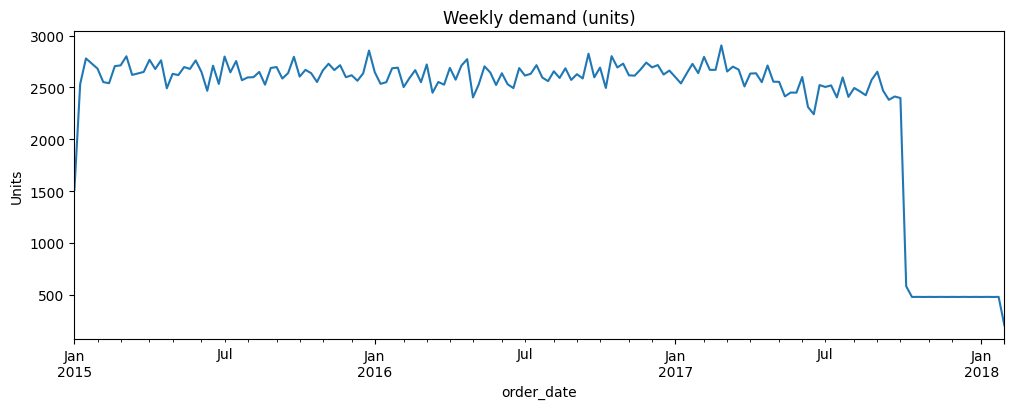

In [ ]:
weekly["y"].plot(figsize=(12, 4), title="Weekly demand (units)")
plt.ylabel("Units")
plt.show()

Chuỗi giảm mạnh từ tháng 10/2017. Bảng bên dưới cho thấy số sản phẩm mỗi tuần giảm từ khoảng 40 xuống 2–3 (product_name) trong khi số đơn hàng giữ nguyên (order_id), nên đây là thay đổi của dataset chứ không phải thay đổi thực của demand.

In [ ]:
mix = df.set_index("order_date").resample("W-SUN").agg({"product_name": "nunique", "order_id": "nunique"})
mix.loc["2017-08-27":"2017-11-05"]

,product_name,order_id
order_date,,
2017-08-27,41,409
2017-09-03,40,409
2017-09-10,40,409
2017-09-17,21,405
2017-09-24,18,393
2017-10-01,22,399
2017-10-08,15,469
2017-10-15,2,479
2017-10-22,2,480


Phần phân tích được giới hạn trong 143 tuần đầy đủ (2015-01-11 đến 2017-10-01). Tuần đầu (2015-01-04, chỉ có 4 ngày) và tuần cuối (2018-02-04, chỉ có 3 ngày) không đầy đủ, và các tuần từ 2017-10-08 trở đi bị ảnh hưởng bởi thay đổi của dataset, nên đều bị loại. Kiểm tra bên dưới xác nhận không thiếu tuần nào trong cửa sổ.

In [ ]:
series = weekly.loc["2015-01-11":"2017-10-01", ["y"]].copy()
series.shape

(143, 1)

In [ ]:
# Missing check: all weeks should be present
all_weeks = pd.date_range(series.index.min(), series.index.max(), freq="W-SUN")
all_weeks.shape, series.shape

((143,), (143, 1))

# **3. Data Partitioning**

Dữ liệu được chia theo thời gian, không chia ngẫu nhiên. 13 tuần cuối (khoảng 91 ngày, chính là horizon cần dự báo) là tập test (2017-07-09 đến 2017-10-01) và 130 tuần trước đó là tập train (2015-01-11 đến 2017-07-02). Tất cả model chỉ được fit trên tập train.

In [ ]:
TEST_WEEKS = 13
train, test = train_test_split(series, test_size=TEST_WEEKS, shuffle=False)

In [ ]:
print("Train:", train.index.min().date(), "→", train.index.max().date(), len(train))
print("Test :", test.index.min().date(), "→", test.index.max().date(), len(test))

Train: 2015-01-11 → 2017-07-02 130
Test : 2017-07-09 → 2017-10-01 13


# **4. Exploratory Data Analysis**

In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 130 entries, 2015-01-11 to 2017-07-02
Freq: W-SUN
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   y       130 non-null    int64
dtypes: int64(1)
memory usage: 2.0 KB


In [ ]:
train["y"].describe()

,y
count,130.000000
mean,2630.092308
std,103.214719
min,2242.000000
25%,2557.250000
50%,2637.000000
75%,2693.750000
max,2906.000000


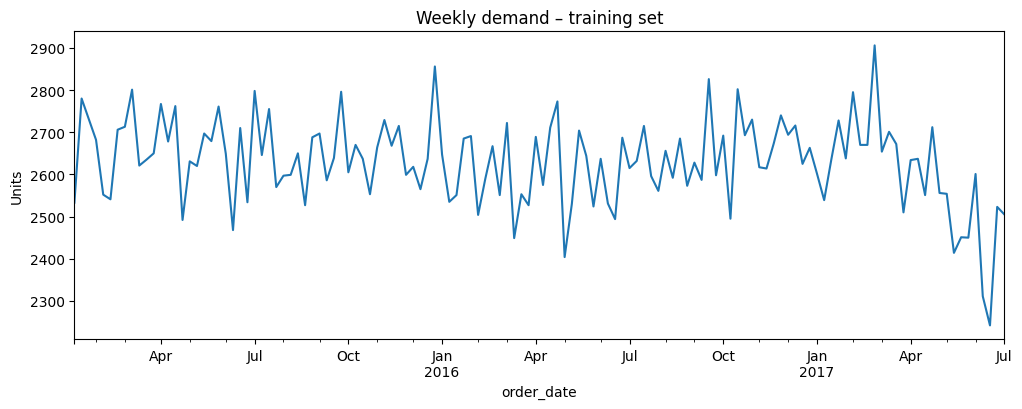

In [ ]:
train["y"].plot(figsize=(12, 4), title="Weekly demand – training set")
plt.ylabel("Units")
plt.show()

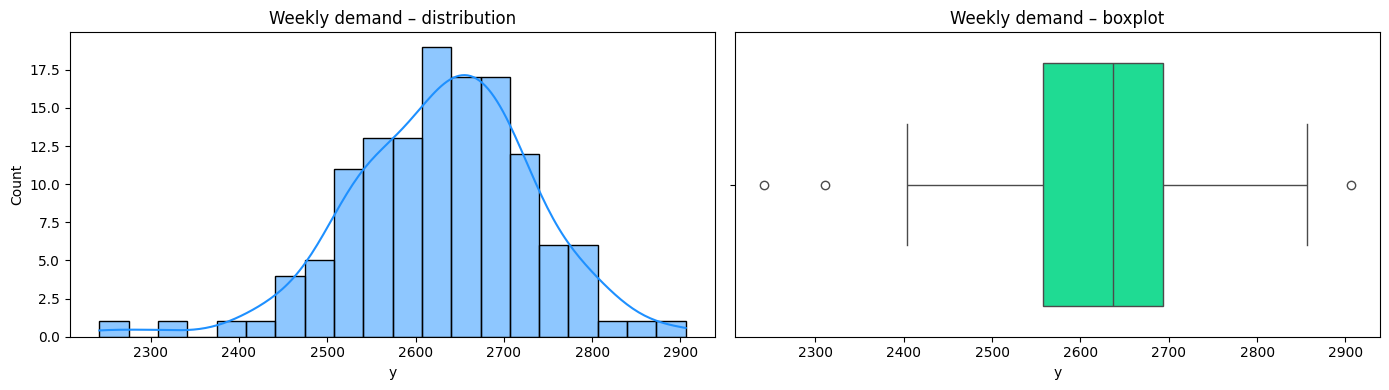

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(data=train, x="y", color="dodgerblue", kde=True, bins=20, ax=axes[0])
axes[0].set_title("Weekly demand – distribution")

sns.boxplot(data=train, x="y", color="mediumspringgreen", ax=axes[1])
axes[1].set_title("Weekly demand – boxplot")

plt.tight_layout()
plt.show()

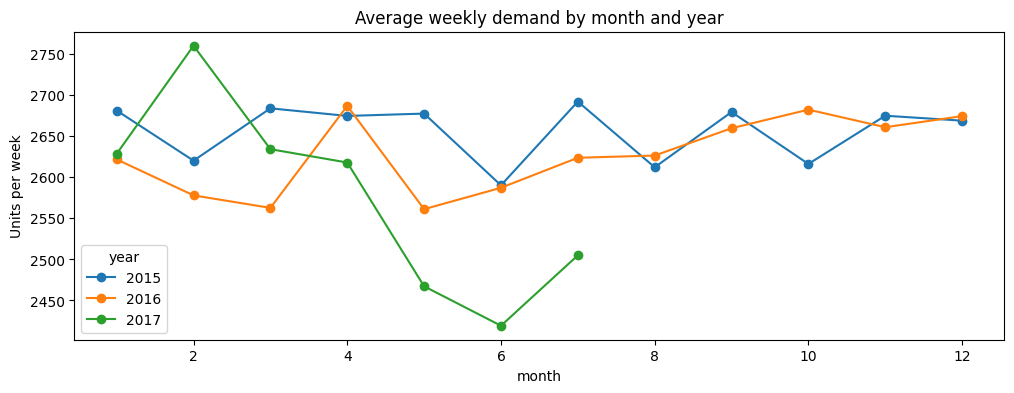

In [ ]:
train_m = train.copy()
train_m["year"] = train_m.index.year
train_m["month"] = train_m.index.month

pivot = train_m.pivot_table(index="month", columns="year", values="y", aggfunc="mean")
pivot.plot(figsize=(12, 4), marker="o", title="Average weekly demand by month and year")
plt.ylabel("Units per week")
plt.show()

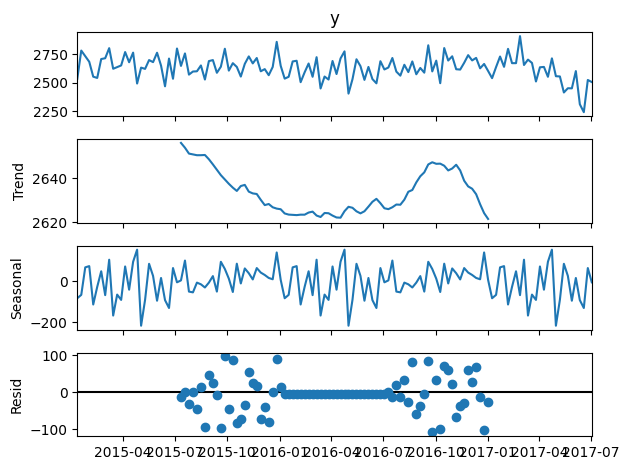

In [ ]:
decomposition_plot = seasonal_decompose(train["y"], model="additive", period=52)
decomposition_plot.plot()
plt.show()

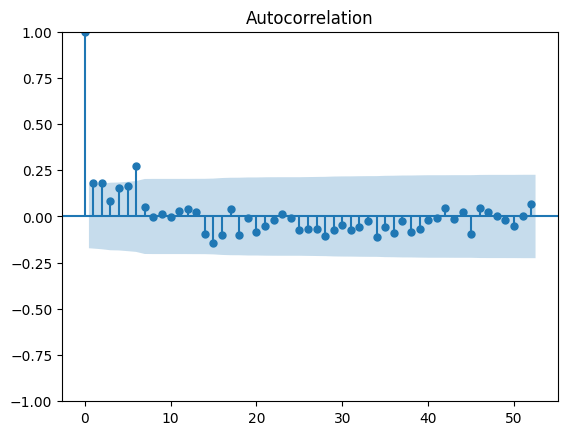

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(train["y"], lags=52)
plt.show()

**Nhận xét (tập train):**
- **Mức và độ dao động:** demand theo tuần trung bình khoảng 2,630 đơn vị (độ lệch chuẩn khoảng 103, từ 2,242 đến 2,906). Phân phối gần hình chuông, có vài tuần thấp bất thường và một tuần cao.
- **Theo tháng:** năm 2015 và 2016 không theo cùng một mẫu từ tháng này sang tháng khác, và từ tháng 4 đến tháng 7/2017 demand thấp hơn cùng kỳ của 2015 và 2016.
- **Decomposition:** trend nằm trong một dải hẹp (khoảng 2,620–2,660 đơn vị) và giảm ở những tuần gần nhất. Thành phần mùa vụ trông không đều, chưa phải một mẫu theo năm rõ rệt, chỉ có 2.5 năm dữ liệu để ước lượng.
- **Tự tương quan:** tương quan dương yếu với các tuần trước (khoảng 0.1–0.2 ở lag 1–5 và khoảng 0.27 ở lag 6) và không có giá trị đáng kể ở lag 52. Vì vậy không có mẫu theo năm mạnh, và các tuần gần đây chỉ cho một chút thông tin về các tuần sau.
- **Ý nghĩa cho việc xây model:** demand dao động quanh một mức ổn định, nên các model đơn giản bám theo mức gần đây có thể đã đủ.

# **5. Model Development**

So sánh năm model: Moving Average (baseline), Simple Exponential Smoothing, Linear Regression theo số thứ tự tuần, Random Forest trên các giá trị trễ (lag) và ANN trên các giá trị trễ. Tất cả đều được fit trên 130 tuần train và dự báo cùng 13 tuần test, nên việc so sánh là công bằng. Các chỉ số (càng thấp càng tốt):

- **MAE:** sai số trung bình, tính bằng đơn vị mỗi tuần.
- **RMSE:** giống MAE nhưng các sai số lớn được tính nặng hơn.
- **MAPE:** sai số trung bình tính theo phần trăm của demand thực tế.

In [ ]:
# Smoothing and ARIMA models
import statsmodels.api as sm
from statsmodels.tsa.api import SimpleExpSmoothing, Holt, ExponentialSmoothing
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Linear Regression and Random Forest
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Metrics
from sklearn.metrics import mean_absolute_error as mae
from sklearn.metrics import mean_absolute_percentage_error as mape
from sklearn.metrics import mean_squared_error

In [ ]:
results = {}

def show_scores(name, actual, pred):
    mae_v = mae(actual, pred)
    rmse_v = np.sqrt(mean_squared_error(actual, pred))
    mape_v = mape(actual, pred)
    results[name] = {"MAE": mae_v, "RMSE": rmse_v, "MAPE (%)": 100 * mape_v}
    print(f"The MAE is {mae_v:.2f}")
    print(f"The RMSE is {rmse_v:.2f}")
    print(f"The MAPE is {100 * mape_v:.2f} %")

**5.1 Moving Average (baseline)**

In [ ]:
pred_ma = pd.Series(train["y"].iloc[-4:].mean(), index=test.index)
show_scores("Moving Average (4)", test["y"], pred_ma)

The MAE is 83.63
The RMSE is 116.01
The MAPE is 3.28 %


Baseline dự báo cả 13 tuần test bằng trung bình của 4 tuần train cuối cùng. Đây là cách đơn giản nhất để bám theo mức gần đây, nên các model khác ít nhất phải tốt bằng nó.

**5.2 Simple Exponential Smoothing**

In [ ]:
model_ses = SimpleExpSmoothing(train["y"], initialization_method="estimated").fit()
pred_ses = model_ses.forecast(len(test))
show_scores("Simple Exp. Smoothing", test["y"], pred_ses)

The MAE is 71.37
The RMSE is 82.96
The MAPE is 2.86 %


Simple Exponential Smoothing (SES) dự báo bằng trung bình có trọng của tất cả các tuần trước, trong đó các tuần gần đây có trọng số lớn hơn. Trọng số (mức làm mượt) được chọn tự động từ dữ liệu train. SES chỉ ước lượng một mức duy nhất, không có xu hướng hay mùa vụ, nên dự báo là một đường phẳng.

**5.3 Linear Regression**

In [ ]:
train["time period"] = range(1, len(train) + 1)
test["time period"] = range(len(train) + 1, len(train) + len(test) + 1)

lr = LinearRegression()
lr.fit(train[["time period"]], train["y"])

pred_lr = pd.Series(lr.predict(test[["time period"]]), index=test.index)
show_scores("Linear Regression", test["y"], pred_lr)

The MAE is 121.35
The RMSE is 137.16
The MAPE is 4.98 %


In [ ]:
print("Coefficient:", lr.coef_[0].round(2), "| Intercept:", round(lr.intercept_, 2))

Coefficient: -0.61 | Intercept: 2669.97


Một đường thẳng được fit theo số thứ tự tuần (1, 2, 3, ...). Hệ số cho biết xu hướng: demand thay đổi trung bình -0.61 đơn vị mỗi tuần (intercept 2,669.97), tức là giảm rất chậm. Đường thẳng không thể theo kịp mức giảm nhanh hơn của những tuần gần nhất.

**5.4 Random Forest**

In [ ]:
rf_lags = 4
lag_df = pd.DataFrame({"y(t)": train["y"]})
for k in range(1, rf_lags + 1):
    lag_df[f"y(t-{k})"] = lag_df["y(t)"].shift(k)
lag_df = lag_df.dropna()

Xtrain_rf = lag_df.drop("y(t)", axis=1)
ytrain_rf = lag_df["y(t)"]

rf_reg = RandomForestRegressor(random_state=99)
rf_reg.fit(Xtrain_rf, ytrain_rf)

RandomForestRegressor(random_state=99)

In [ ]:
history = list(train["y"].iloc[-rf_lags:])
preds = []
for _ in range(len(test)):
    x = pd.DataFrame([history[::-1][:rf_lags]], columns=Xtrain_rf.columns)
    p = rf_reg.predict(x)[0]
    preds.append(p)
    history.append(p)

pred_rf = pd.Series(preds, index=test.index)
show_scores("Random Forest (lags)", test["y"], pred_rf)

The MAE is 157.32
The RMSE is 180.55
The MAPE is 6.46 %


Random Forest dùng 4 tuần trước làm đầu vào để dự đoán tuần kế tiếp. Để dự báo 13 tuần, mỗi dự đoán được thêm vào lịch sử và dùng làm đầu vào cho tuần sau (dự báo đệ quy). Model dạng cây không thể vượt ra ngoài các giá trị đã thấy khi huấn luyện, nên có xu hướng ở gần mức trung bình của tập train.

**5.5 Deep Learning (ANN)**

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler

tf.random.set_seed(42)

In [ ]:
scaler = StandardScaler()
train_scaled = scaler.fit_transform(train[["y"]])      # fit on train only

ann_lags = 8

def make_windows(values, ann_lags):
    X, y = [], []
    for i in range(ann_lags, len(values)):
        X.append(values[i - ann_lags:i, 0])
        y.append(values[i, 0])
    return np.array(X), np.array(y)

Xtrain_dl, ytrain_dl = make_windows(train_scaled, ann_lags)
Xtrain_dl.shape, ytrain_dl.shape

((122, 8), (122,))

In [ ]:
ann = Sequential([
    Input(shape=(ann_lags,)),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

ann.compile(optimizer=Adam(0.001), loss="mse", metrics=["mae"])

early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

history = ann.fit(Xtrain_dl, ytrain_dl,
                  epochs=200,
                  batch_size=16,
                  validation_split=0.2,
                  callbacks=[early_stop],
                  verbose=0)

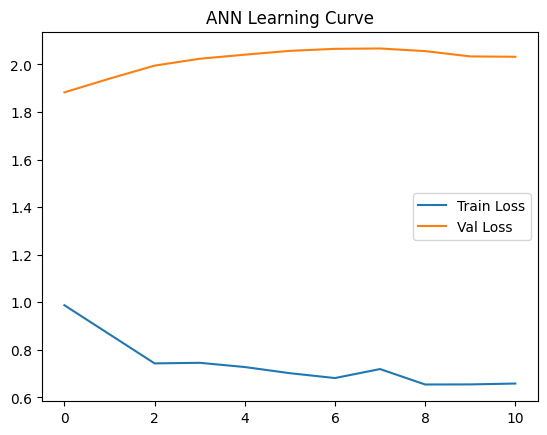

In [ ]:
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.legend()
plt.title("ANN Learning Curve")
plt.show()

In [ ]:
window_vals = list(train_scaled[-ann_lags:, 0])
preds_scaled = []

for _ in range(len(test)):
    x = np.array(window_vals[-ann_lags:]).reshape(1, -1)
    p = ann.predict(x, verbose=0)[0, 0]
    preds_scaled.append(p)
    window_vals.append(p)

pred_ann = pd.Series(
    scaler.inverse_transform(np.array(preds_scaled).reshape(-1, 1)).flatten(),
    index=test.index
)
show_scores("ANN (MLP)", test["y"], pred_ann)

The MAE is 130.18
The RMSE is 146.65
The MAPE is 5.32 %


Một mạng nơ-ron nhỏ (hai lớp ẩn với 32 và 16 nơ-ron) dùng 8 tuần trước (đã chuẩn hóa) để dự đoán tuần kế tiếp. `EarlyStopping` dừng huấn luyện khi validation loss không còn cải thiện, để tránh overfitting. Giống Random Forest, 13 tuần test được dự báo đệ quy. Dữ liệu huấn luyện nhỏ (122 cửa sổ), nên không kỳ vọng model này cải thiện nhiều.

# **Model Comparison**

In [ ]:
comparison = pd.DataFrame(results).T.round(2).sort_values("MAE")
comparison

,MAE,RMSE,MAPE (%)
Simple Exp. Smoothing,71.37,82.96,2.86
Moving Average (4),83.63,116.01,3.28
Linear Regression,121.35,137.16,4.98
ANN (MLP),130.18,146.65,5.32
Random Forest (lags),157.32,180.55,6.46


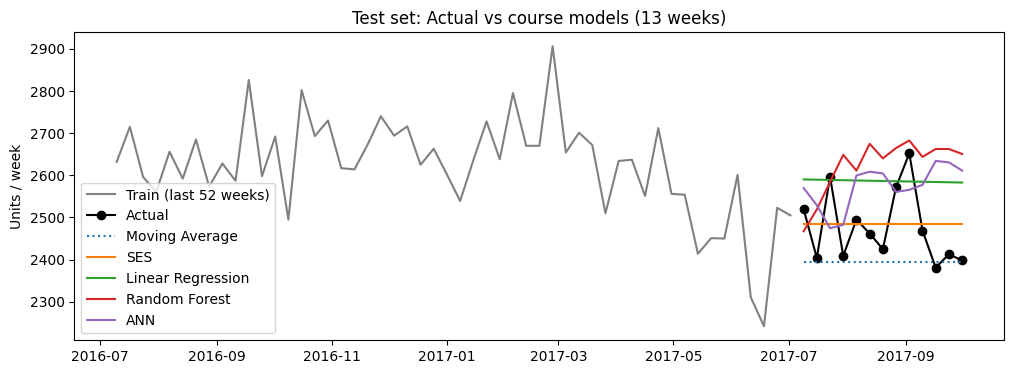

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(train.index[-52:], train["y"].iloc[-52:], label="Train (last 52 weeks)", color="grey")
plt.plot(test.index, test["y"], label="Actual", color="black", marker="o")
plt.plot(test.index, pred_ma, label="Moving Average", linestyle=":")
plt.plot(test.index, pred_ses, label="SES")
plt.plot(test.index, pred_lr, label="Linear Regression")
plt.plot(test.index, pred_rf, label="Random Forest")
plt.plot(test.index, pred_ann, label="ANN")
plt.title("Test set: Actual vs course models (13 weeks)")
plt.ylabel("Units / week")
plt.legend()
plt.show()

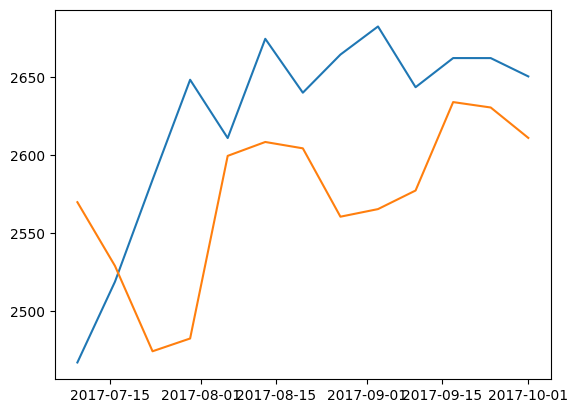

In [ ]:
plt.plot(test.index, pred_rf, label="Random Forest")
plt.plot(test.index, pred_ann, label="ANN")

- **SES là model tốt nhất** (MAE 71.37, RMSE 82.96, MAPE 2.86%), tiếp theo là Moving Average 4 tuần (MAE 83.63). Cả hai đều chỉ bám theo mức demand gần đây. SES còn có RMSE thấp hơn nhiều (82.96 so với 116.01), nghĩa là ít sai số lớn hơn.
- **Linear Regression** (MAE 121.35) kém hơn vì đường thẳng chỉ giảm 0.61 đơn vị mỗi tuần, nên dự báo vẫn ở quanh 2,585 đơn vị, cao hơn phần lớn các tuần test.
- **ANN** (MAE 130.18) và **Random Forest** (MAE 157.32) còn kém hơn. Hai model dự báo đệ quy và có xu hướng quay về mức trung bình của tập train (khoảng 2,630 đơn vị) thay vì theo mức demand thấp hơn gần đây. Với chỉ 130 tuần dữ liệu, chúng không học được nhiều hơn các model đơn giản.
- **Phát hiện chính:** model đơn giản nhất thắng. Điều này khớp với EDA: mùa vụ yếu, tự tương quan yếu và mức demand ổn định.
- **Quyết định:** chọn SES làm model cuối.
- Model được chọn bằng một tập test gồm 13 tuần, nên thứ hạng của các model có kết quả gần nhau cần đọc thận trọng.

# **Final Model and Short-Term Demand Insight**

Model tốt nhất là Simple Exponential Smoothing, được fit lại trên toàn bộ 143 tuần (gộp cả tuần train và test) và dự báo 13 tuần tiếp theo (2017-10-08 đến 2017-12-31). Vì SES chỉ ước lượng một mức duy nhất nên dự báo có cùng một giá trị (2,463 đơn vị) ở mọi tuần.

In [ ]:
# Final model: refit on all 143 weeks and forecast the next 13 weeks
final_model = SimpleExpSmoothing(series["y"], initialization_method="estimated").fit()
forecast_13 = final_model.forecast(13)
forecast_13.index = pd.date_range(series.index[-1] + pd.Timedelta(weeks=1), periods=13, freq="W-SUN")
forecast_13.round(0)

,0
2017-10-08,2463.0
2017-10-15,2463.0
2017-10-22,2463.0
2017-10-29,2463.0
2017-11-05,2463.0
2017-11-12,2463.0
2017-11-19,2463.0
2017-11-26,2463.0
2017-12-03,2463.0
2017-12-10,2463.0


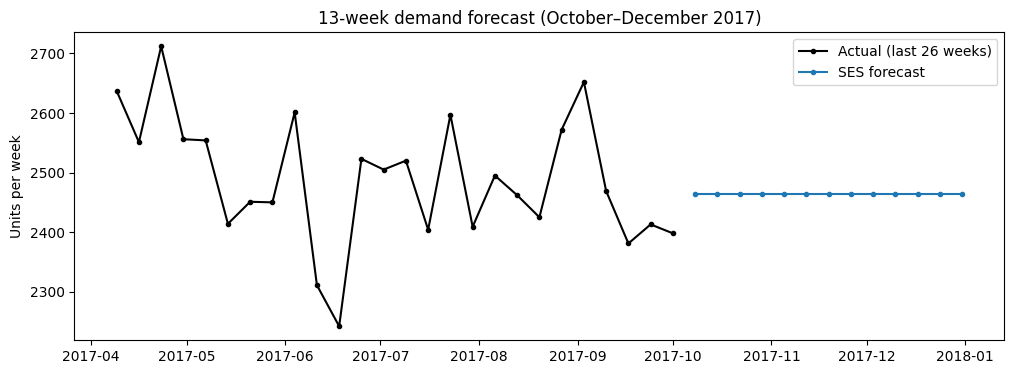

In [ ]:
# Chart: last 26 weeks and the forecast
plt.figure(figsize=(12, 4))
plt.plot(series.index[-26:], series["y"].iloc[-26:], label="Actual (last 26 weeks)", color="black", marker="o", ms=3)
plt.plot(forecast_13.index, forecast_13, label="SES forecast", color="tab:blue", marker="o", ms=3)
plt.title("13-week demand forecast (October–December 2017)")
plt.ylabel("Units per week")
plt.legend()
plt.show()

In [ ]:
# Short-Term Demand Insight: compare with two benchmarks
last13 = series["y"].tail(13)
same_ly = series["y"].reindex(forecast_13.index - pd.Timedelta(weeks=52))

fc_total = forecast_13.sum()
insight = pd.DataFrame({
    "Total units (13 weeks)": [fc_total, last13.sum(), same_ly.sum()],
    "Mean units per week": [forecast_13.mean(), last13.mean(), same_ly.mean()]
}, index=["SES forecast (Oct–Dec 2017)",
          "Last 13 actual weeks (Jul–Sep 2017)",
          "Same period last year (Oct–Dec 2016)"])
insight["Forecast vs benchmark (%)"] = (fc_total / insight["Total units (13 weeks)"] - 1) * 100
insight.round(1)

,Total units (13 weeks),Mean units per week,Forecast vs benchmark (%)
SES forecast (Oct–Dec 2017),32021.9,2463.2,0.0
Last 13 actual weeks (Jul–Sep 2017),32197.0,2476.7,-0.5
Same period last year (Oct–Dec 2016),34664.0,2666.5,-7.6


In [ ]:
# Rough planning range: forecast ± typical weekly error on the test set (MAE of SES)
typical_error = results["Simple Exp. Smoothing"]["MAE"]
print(f"Planning range per week: {forecast_13.mean() - typical_error:,.0f} – {forecast_13.mean() + typical_error:,.0f} units")

Planning range per week: 2,392 – 2,535 units


**Nhận định nhu cầu ngắn hạn:**
- **Dự báo:** khoảng 2,463 đơn vị mỗi tuần, tổng 32,022 đơn vị trong 13 tuần.
- **So sánh:** thấp hơn 0.5% so với 13 tuần thực tế gần nhất (32,197 đơn vị) và thấp hơn 7.6% so với cùng kỳ năm 2016 (34,664 đơn vị). Vì vậy demand dự kiến giữ ở mức thấp của năm 2017 và không quay lại mức của năm 2016.
- **Khoảng lập kế hoạch:** khoảng 2,392–2,535 đơn vị mỗi tuần (dự báo ± sai số điển hình trên tập test khoảng 71 đơn vị). Khoảng này chỉ là hướng dẫn thô, không phải khoảng tin cậy thống kê.
- **Hàm ý:** năng lực xử lý hàng tuần cho quý 4/2017 nên được lập quanh mức 2,400–2,550 đơn vị, không phải quanh mức của năm 2016 (khoảng 2,667 đơn vị mỗi tuần). Vì dự báo là đường phẳng nên không thể hiển thị các đỉnh theo tuần, và dữ liệu cũng không cho thấy đỉnh rõ rệt ở quý 4.

# Kết luận và hạn chế

**Kết luận:** Demand theo tuần dao động quanh một mức ổn định và mùa vụ yếu. Model SES đơn giản cho sai số thấp nhất trên tập test (MAE 71.37, MAPE 2.86%) và tốt hơn các model phức tạp hơn (Linear Regression, Random Forest và ANN). Model dự báo khoảng 2,463 đơn vị mỗi tuần cho tháng 10–12/2017, thấp hơn một chút so với các tuần gần đây và thấp hơn 7.6% so với một năm trước.

**Hạn chế:**
- Model được chọn bằng một tập test gồm 13 tuần, nên thứ hạng của các model có kết quả gần nhau cần đọc thận trọng.
- Random Forest và ANN không được tinh chỉnh, và chỉ có 130 tuần dữ liệu huấn luyện.
- Dự báo của SES là một đường phẳng: không cho thấy dao động theo tuần và không có khoảng tin cậy thống kê. Khoảng dự báo ± MAE chỉ là hướng dẫn thô.
- Các tuần sau 2017-10-01 bị loại vì dataset thay đổi cấu trúc, nên không thể kiểm chứng dự báo với dữ liệu thật.
- Kết quả của Random Forest và ANN có thể thay đổi nhẹ giữa các lần chạy.
- Sai số của chúng ta tính trên demand theo tuần chưa làm mượt qua 13 tuần liên tiếp. Repo tham chiếu báo cáo MAE thấp hơn (40.4) nhưng trên chuỗi đã được lọc và làm mượt, nên hai kết quả không so sánh được.